================ DISPONIBILIDAD EN MAST ================
SearchResult containing 2 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 91 2025    QLP     200   117831881      0.0
  1 TESS Sector 92 2025    QLP     200   117831881      0.0


########################################################################
### EJECUTANDO PIPELINE: QLP
########################################################################
[QLP] Autor seleccionado: QLP | columna: sap_flux
SearchResult containing 2 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 91 2025    QLP     200   117831881      0.0
  1 TESS Sector 92 2025    QLP     200   117831881      0.0
  S91: CBV no aplicado (Assertio

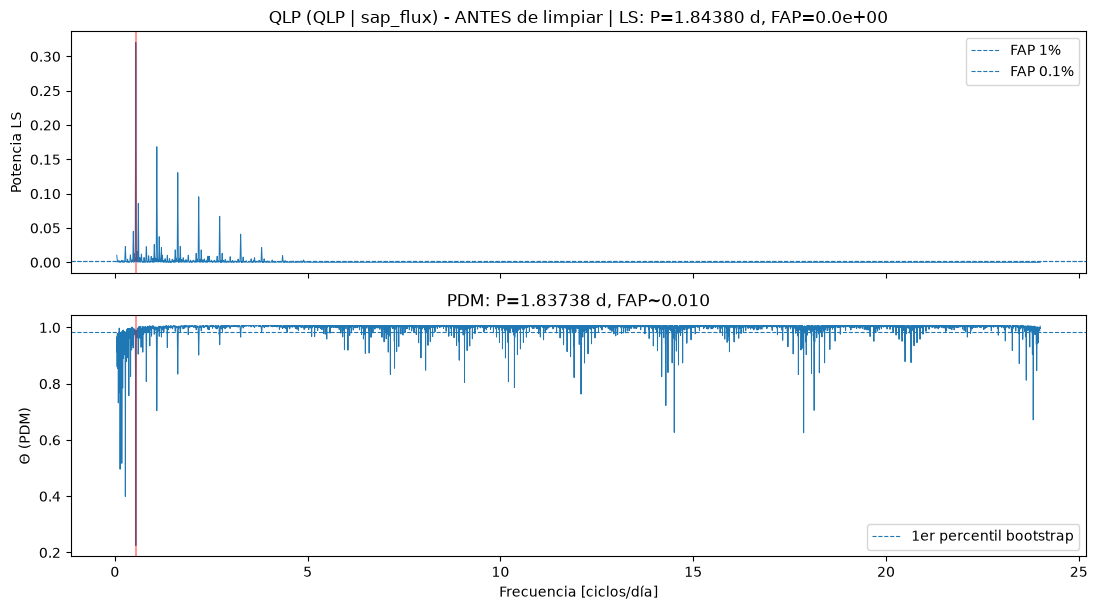


[QLP] Periodo PDM fino inicial: P = 3.678535 d | T0 = 3775.44745

O-C: 18 eclipses medidos (8 primarios, 10 secundarios), 4 discrepantes
  P_OC = 3.678549 +- 0.000320 d   (P_PDM fino: 3.678535 d)
  dispersión del O-C (buenos) = 6.7 min
  descartado por O-C: secundario BTJD 3777.157, O-C = -27.1 min
  descartado por O-C: secundario BTJD 3791.902, O-C = +17.4 min
  descartado por O-C: secundario BTJD 3810.264, O-C = -27.0 min
  descartado por O-C: secundario BTJD 3825.014, O-C = +24.2 min


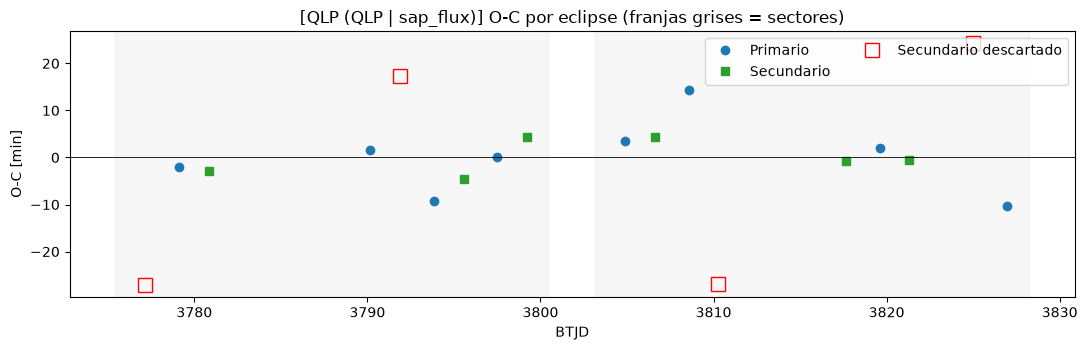

[QLP] Periodo adoptado para plegado y limpieza: P = 3.678535 d

[Análisis por Ciclo Orbital] Total ciclos: 14 | Ciclos descartados completos: 0


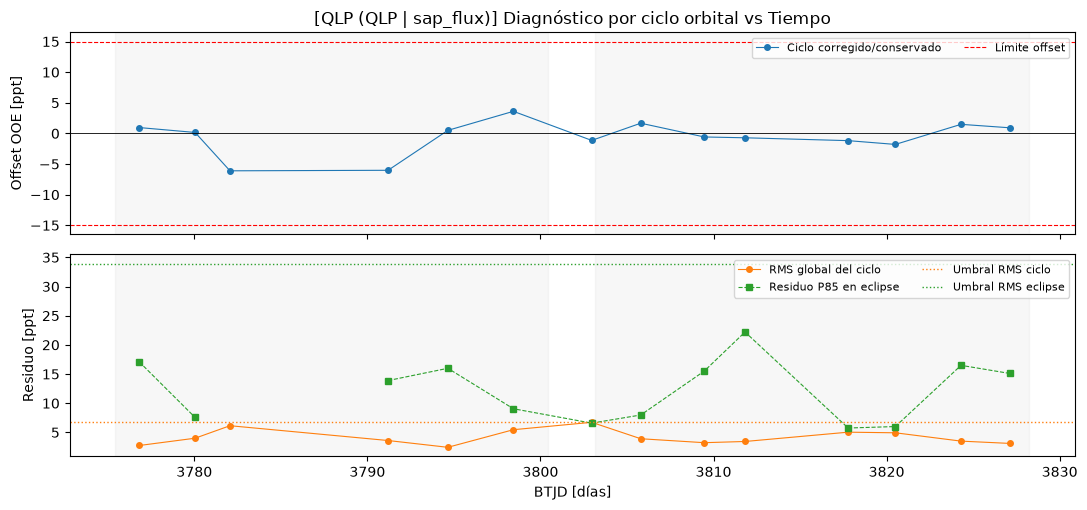

[QLP] Periodo re-afinado tras nivelar ciclos: P = 3.678619 d
  iteración 1: 837 puntos fuera de plantilla (+837 en este paso; 118 en ventana de eclipse)
  iteración 2: 1031 puntos fuera de plantilla (+194 en este paso; 142 en ventana de eclipse)
  iteración 3: 1130 puntos fuera de plantilla (+100 en este paso; 159 en ventana de eclipse)
  iteración 4: 1176 puntos fuera de plantilla (+47 en este paso; 169 en ventana de eclipse)
  iteración 5: 1209 puntos fuera de plantilla (+34 en este paso; 175 en ventana de eclipse)
  iteración 6: 1226 puntos fuera de plantilla (+17 en este paso; 176 en ventana de eclipse)
  iteración 7: 1230 puntos fuera de plantilla (+5 en este paso; 176 en ventana de eclipse)
  iteración 8: 1240 puntos fuera de plantilla (+10 en este paso; 176 en ventana de eclipse)

================ RESUMEN DE LIMPIEZA [QLP (QLP | sap_flux)] ================
Total puntos iniciales (tras reducción base): 15939
  - Removidos por ciclo orbital anómalo : 0 (0.00 %)
  - Removidos por e

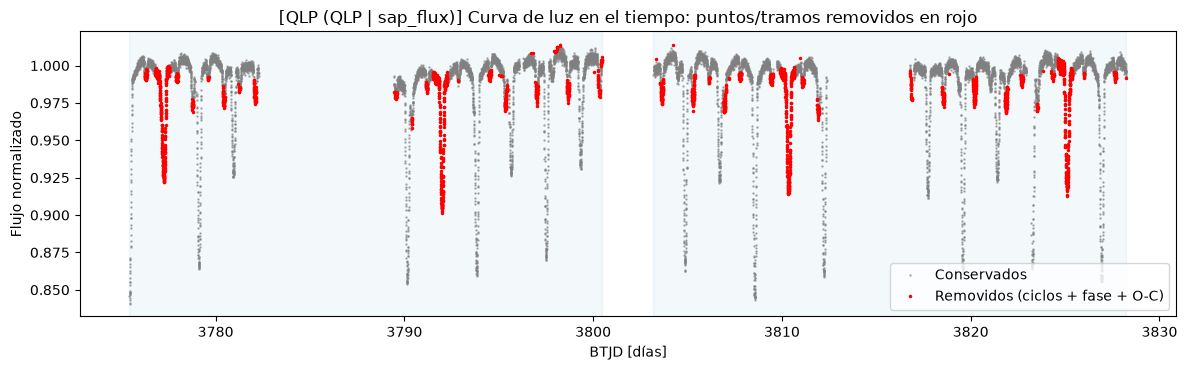

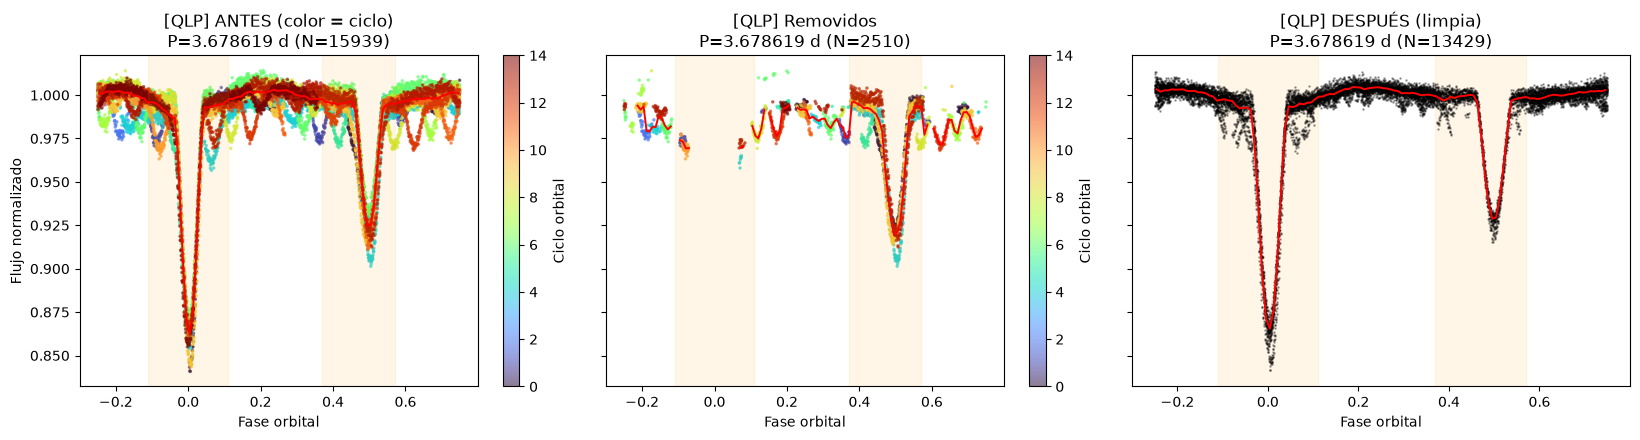


[QLP (QLP | sap_flux) - DESPUÉS de limpiar] N=13429, baseline=52.81 d
  LS : P = 1.843799 d (2xP = 3.687598 d), potencia = 0.3300, FAP = 0.00e+00
  PDM: P = 1.837384 d (2xP = 3.674767 d), theta_min = 0.1874, FAP ~ 0.010 (mínimo resoluble 1/101)


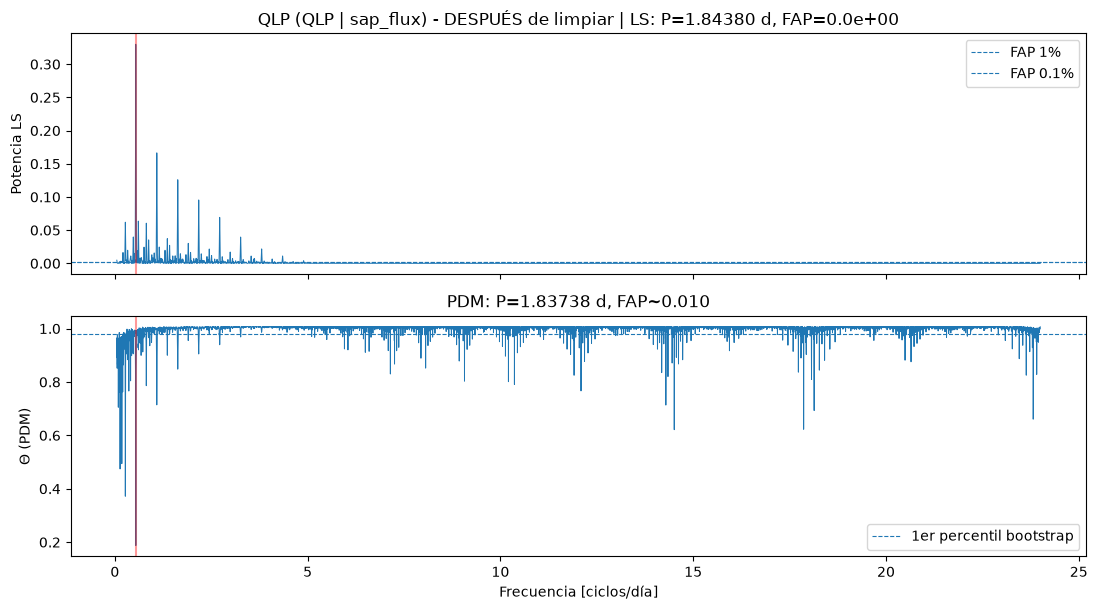

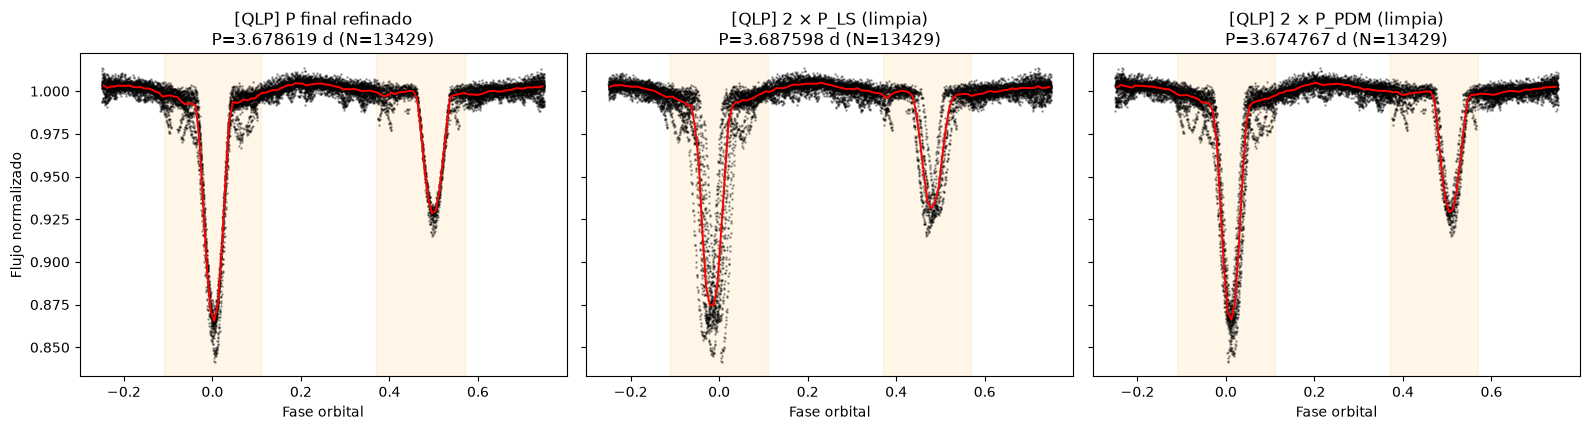


########################################################################
### EJECUTANDO PIPELINE: SPOC
########################################################################
[SPOC] Sin resultados en MAST para author='SPOC'.
[SPOC] author='TESS-SPOC' existe en otros sectores, pero no en ['TESS Sector 91', 'TESS Sector 92'].
[SPOC] AVISO: No se encontraron datos para autores ['SPOC', 'TESS-SPOC'] en ['TESS Sector 91', 'TESS Sector 92'].


In [ ]:
"""
TIC 117831881 (QLP + SPOC / TESS-SPOC, S91 + S92) - versión 4
  1) Inspección de disponibilidad en MAST (QLP, SPOC, TESS-SPOC)
  2) Reducción base diferenciada:
       - QLP        : sap_flux + CBV tipo SPOC + nivelación por segmento (sin recorte inferior)
       - SPOC       : pdcsap_flux oficial (PDC-MAP) sin doble CBV + nivelación por segmento
       - (Opcional) : SPOC sap_flux + CBV manual + corrección CROWDSAP
  3) Lomb-Scargle + PDM con FAP (antes y después de limpiar)
  4) Efeméride O-C robusta por eclipse
  5) Diagnóstico, nivelación OOE y descarte por CICLO ORBITAL completo
  6) Limpieza iterativa en fase (con protección inteligente de eclipses)
  7) Exportación independiente (.fits / .txt) y comparación directa QLP vs SPOC
Código autocontenido, apto para pegar en una celda de Jupyter.
"""
import numpy as np
import matplotlib.pyplot as plt
import lightkurve as lk
import astropy.units as u
from astropy.timeseries import LombScargle
from scipy.ndimage import median_filter

# ======================= PARÁMETROS CONFIGURABLES =======================
TIC = "TIC 117831881"
SECTORES = ["TESS Sector 91", "TESS Sector 92"]
SEED = 42

# Cadencia preferida [s] si SPOC ofrece varias en el mismo sector (p. ej. 20 s y 120 s)
PREFERIR_EXPTIME_SPOC = 120.0
APLICAR_CROWDSAP_EN_SAP = True  # corrige dilución por vecinos en sap_flux si existe CROWDSAP

# Pipelines a ejecutar secuencialmente
PIPELINES = [
    dict(
        nombre="QLP",
        autores=["QLP"],
        flux_column="sap_flux",
        aplicar_cbv=True,
        cbv_types=["SingleScale", "Spike"],
    ),
    dict(
        nombre="SPOC",
        autores=["SPOC", "TESS-SPOC"],   # usa SPOC 2-min si existe; si no, FFI TESS-SPOC
        flux_column="pdcsap_flux",       # reducción oficial PDC-MAP (NO reaplicar CBV)
        aplicar_cbv=False,
        cbv_types=[],
    ),
    # Descomenta este bloque si también quieres auditar SPOC partiendo desde sap_flux + CBV manual:
    # dict(
    #     nombre="SPOC_SAP_CBV",
    #     autores=["SPOC", "TESS-SPOC"],
    #     flux_column="sap_flux",
    #     aplicar_cbv=True,
    #     cbv_types=["SingleScale", "Spike"],
    # ),
]

# --- 1. Reducción base (dominio del tiempo) ---
VENTANA_DIAS = 0.5            # ventana de la mediana móvil para picos superiores
SIGMA_SUP_TIEMPO = 3.5        # SOLO recorte superior (flares/rayos cósmicos)
GAP_DIAS = 0.4                # salto temporal que define un nuevo segmento/órbita TESS

# --- 2. Periodogramas ---
FMIN, FMAX = 0.05, 24.0       # rango de frecuencias [ciclos/día]
OVERSAMPLE = 10
BIN_MIN = 20                  # binning (min) para acelerar PDM global y su bootstrap
PDM_NBINS = 20
N_BOOT = 100                  # iteraciones bootstrap para FAP de PDM

# --- 3. Periodo y ventanas de fase ---
P_MANUAL = None               # None = FACTOR_PERIODO * P_LS refinado con PDM fino
FACTOR_PERIODO = 2            # 2 para binarias eclipsantes simétricas/casi-simétricas
REFINAR_PERIODO = True        # afina P con PDM de alta resolución (+-0.5 %)
USAR_P_OC = False             # True: usa P de medir_oc; False: conserva P_PDM fino

PROTEGER_FASE = [(-0.11, 0.11), (0.37, 0.57)]

# --- 4. Análisis por eclipse (O-C) ---
HALF_WIN_FASE = 0.10
SEC_FASE = 0.47
OC_RANGO_D = 0.25
OC_SIGMA = 3.0
OC_MIN_D = 0.004

# --- 5. Detección y corrección por CICLO ORBITAL ---
CORREGIR_OFFSET_CICLO = True
CORREGIR_RAMPA_CICLO = True
MAX_OFFSET_CORREGIBLE = 0.015
SIGMA_RMS_CICLO = 2.5
SIGMA_ECL_CICLO = 2.8
MIN_PUNTOS_OOE_CICLO = 15

# --- 6. Limpieza iterativa en fase ---
FASE_NBINS = 160
K_INF, K_SUP = 2.8, 3.0
K_ECLIPSE_EXTREMO = 5.5
N_ITER = 8


# ======================= 1) DESCARGA Y REDUCCIÓN BASE =======================
def inspeccionar_disponibilidad():
    """Muestra qué autores y cadencias existen en MAST para el objeto en los sectores pedidos."""
    sr_all = lk.search_lightcurve(TIC)
    print("================ DISPONIBILIDAD EN MAST ================")
    if len(sr_all) == 0:
        print(f"No se encontraron curvas para {TIC} en MAST.")
        print("========================================================\n")
        return sr_all

    sr_sec = sr_all[np.isin(sr_all.mission, SECTORES)]
    if len(sr_sec) == 0:
        print(f"No se encontraron curvas para {TIC} en {SECTORES}.")
        print("Productos disponibles en otros sectores:")
        print(sr_all)
    else:
        print(sr_sec)
    print("========================================================\n")
    return sr_sec


def _seleccionar_una_cadencia_por_sector(sr, exptime_pref=PREFERIR_EXPTIME_SPOC):
    """Evita descargar cadencias duplicadas (ej. 20 s y 120 s) dentro de un mismo sector."""
    idx_keep = []
    misiones = np.asarray(sr.mission)
    exptimes = np.asarray(sr.exptime.value, dtype=float)
    for sec in SECTORES:
        cand = np.where(misiones == sec)[0]
        if len(cand) == 0:
            continue
        if len(cand) == 1:
            idx_keep.append(int(cand[0]))
        else:
            mejor = cand[np.argmin(np.abs(exptimes[cand] - exptime_pref))]
            idx_keep.append(int(mejor))
    return sr[idx_keep]


def descargar_pipeline(cfg):
    """Descarga las curvas del primer autor disponible dentro de cfg['autores']."""
    nombre = cfg["nombre"]
    flux_col = cfg["flux_column"]
    for autor in cfg["autores"]:
        sr = lk.search_lightcurve(TIC, author=autor)
        if len(sr) == 0:
            print(f"[{nombre}] Sin resultados en MAST para author='{autor}'.")
            continue

        sr = sr[np.isin(sr.mission, SECTORES)]
        if len(sr) == 0:
            print(f"[{nombre}] author='{autor}' existe en otros sectores, pero no en {SECTORES}.")
            continue

        sr = _seleccionar_una_cadencia_por_sector(sr)
        print(f"[{nombre}] Autor seleccionado: {autor} | columna: {flux_col}")
        print(sr)
        try:
            lcs = sr.download_all(quality_bitmask="hard", flux_column=flux_col)
            return lcs, autor, flux_col
        except Exception as e:
            print(f"[{nombre}] Falló descarga con '{flux_col}' ({type(e).__name__}: {e}). "
                  f"Reintentando con 'sap_flux'...")
            lcs = sr.download_all(quality_bitmask="hard", flux_column="sap_flux")
            return lcs, autor, "sap_flux"

    print(f"[{nombre}] AVISO: No se encontraron datos para autores {cfg['autores']} en {SECTORES}.")
    return None, None, None


def corregir_dilucion_crowdsap(lc):
    """
    Replica la corrección de dilución de SPOC PDC-MAP sobre sap_flux cuando CROWDSAP está disponible:
      F_corr = F - (1 - CROWDSAP) * F_continuo
    Restaura la profundidad real de los eclipses ante contaminación por estrellas vecinas.
    """
    crowd = lc.meta.get("CROWDSAP", None)
    if crowd is None or not np.isfinite(crowd) or not (0.0 < float(crowd) < 1.0):
        return lc
    crowd = float(crowd)
    f = np.asarray(lc.flux.value, dtype=np.float64)
    f_cont = np.nanpercentile(f, 70)
    f_corr = f - (1.0 - crowd) * f_cont
    lc_out = lc.copy()
    lc_out.flux = f_corr * lc.flux.unit
    print(f"  S{lc.meta.get('SECTOR')}: corrección de dilución aplicada (CROWDSAP={crowd:.4f})")
    return lc_out


def cotrending_cbv(lc, cbv_types):
    """Aplica CBVCorrector solo cuando se trabaja desde sap_flux (nunca sobre pdcsap_flux)."""
    if not cbv_types:
        return lc
    cbv_indices = [np.arange(1, 9) if ct != "Spike" else "ALL" for ct in cbv_types]
    try:
        cbvc = lk.correctors.CBVCorrector(lc)
        cbvc.correct(cbv_type=cbv_types, cbv_indices=cbv_indices)
        print(f"  S{lc.meta.get('SECTOR')}: CBV aplicado ({', '.join(cbv_types)})")
        return cbvc.corrected_lc
    except Exception as e:
        print(f"  S{lc.meta.get('SECTOR')}: CBV no aplicado ({type(e).__name__}: {e})")
        return lc


def clip_superior_y_nivelar_segmentos(lc):
    """
    1) Nivela cada órbita de TESS con su percentil 70 (inmune a eclipses).
    2) Recorta SOLO picos superiores por segmento (separados por GAP_DIAS).
    """
    t = np.asarray(lc.time.value, dtype=np.float64)
    f = np.asarray(lc.flux.value, dtype=np.float64)
    dt = np.nanmedian(np.diff(t))
    n = max(3, int(VENTANA_DIAS / dt) | 1)

    cortes = np.where(np.diff(t) > GAP_DIAS)[0] + 1
    ini = np.r_[0, cortes]
    fin = np.r_[cortes, len(t)]

    tend = np.empty_like(f)
    f_niv = np.empty_like(f)
    escala_seg = np.empty_like(f)
    for a, b in zip(ini, fin):
        seg = f[a:b]
        nivel_seg = np.nanpercentile(seg, 70)
        seg_norm = seg / nivel_seg
        f_niv[a:b] = seg_norm
        escala_seg[a:b] = nivel_seg
        tend[a:b] = median_filter(seg_norm, size=min(n, (b - a) | 1), mode="nearest")

    resid = f_niv - tend
    sig = 1.4826 * np.nanmedian(np.abs(resid - np.nanmedian(resid)))
    buenos = resid < SIGMA_SUP_TIEMPO * sig
    print(f"  S{lc.meta.get('SECTOR')}: {len(ini)} segmentos/órbitas | dt~{dt*1440:.1f} min | "
          f"picos superiores removidos: {(~buenos).sum()} de {len(lc)}")

    lc_out = lc[buenos].copy()
    lc_out.flux = f_niv[buenos] * u.dimensionless_unscaled
    if lc_out.flux_err is not None:
        err_val = np.asarray(lc.flux_err.value, dtype=np.float64)[buenos]
        lc_out.flux_err = (err_val / escala_seg[buenos]) * u.dimensionless_unscaled
    return lc_out


def reducir_base(lc, aplicar_cbv, cbv_types, es_pdcsap):
    lc = lc.remove_nans()
    if hasattr(lc, "quality") and lc.quality is not None:
        lc = lc[lc.quality == 0]
    if es_pdcsap:
        print(f"  S{lc.meta.get('SECTOR')}: usando pdcsap_flux oficial de SPOC (sin doble CBV)")
    else:
        lc = cotrending_cbv(lc, cbv_types).remove_nans()
        if APLICAR_CROWDSAP_EN_SAP:
            lc = corregir_dilucion_crowdsap(lc)
    lc = clip_superior_y_nivelar_segmentos(lc)
    return lc


# ======================= 2) PERIODOGRAMAS =======================
def bin_tiempo(t, y, minutos):
    w = minutos / 1440.0
    k = np.floor((t - t.min()) / w).astype(int)
    cnt = np.bincount(k)
    ok = cnt > 0
    tb = np.bincount(k, weights=t)[ok] / cnt[ok]
    yb = np.bincount(k, weights=y)[ok] / cnt[ok]
    return tb, yb


def pdm_theta(t, y, freqs, nbins=PDM_NBINS):
    var = np.var(y, ddof=1)
    theta = np.empty(len(freqs))
    for i, f in enumerate(freqs):
        idx = (((t * f) % 1.0) * nbins).astype(int)
        cnt = np.bincount(idx, minlength=nbins)
        s1 = np.bincount(idx, weights=y, minlength=nbins)
        s2 = np.bincount(idx, weights=y * y, minlength=nbins)
        ok = cnt > 1
        ss = (s2[ok] - s1[ok] ** 2 / cnt[ok]).sum()
        dof = (cnt[ok] - 1).sum()
        theta[i] = (ss / dof) / var
    return theta


def analizar(t, y, titulo):
    baseline = t.max() - t.min()
    freq = np.arange(FMIN, FMAX, 1.0 / (OVERSAMPLE * baseline))

    ls = LombScargle(t, y)
    power = ls.power(freq)
    i_ls = np.argmax(power)
    P_ls = 1.0 / freq[i_ls]
    fap_ls = ls.false_alarm_probability(power[i_ls], minimum_frequency=FMIN,
                                        maximum_frequency=FMAX, method="baluev")
    niveles = ls.false_alarm_level([0.01, 0.001], minimum_frequency=FMIN,
                                   maximum_frequency=FMAX, method="baluev")

    tb, yb = bin_tiempo(t, y, BIN_MIN)
    theta = pdm_theta(tb, yb, freq)
    i_pdm = np.argmin(theta)
    P_pdm = 1.0 / freq[i_pdm]
    rng = np.random.default_rng(SEED)
    min_boot = np.array([pdm_theta(tb, rng.permutation(yb), freq).min() for _ in range(N_BOOT)])
    fap_pdm = (np.sum(min_boot <= theta[i_pdm]) + 1) / (N_BOOT + 1)

    print(f"\n[{titulo}] N={len(t)}, baseline={baseline:.2f} d")
    print(f"  LS : P = {P_ls:.6f} d (2xP = {2*P_ls:.6f} d), potencia = {power[i_ls]:.4f}, FAP = {fap_ls:.2e}")
    print(f"  PDM: P = {P_pdm:.6f} d (2xP = {2*P_pdm:.6f} d), theta_min = {theta[i_pdm]:.4f}, FAP ~ {fap_pdm:.3f}"
          f" (mínimo resoluble 1/{N_BOOT + 1})")

    fig, axs = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True)
    axs[0].plot(freq, power, lw=0.7)
    for nv, lab in zip(niveles, ["FAP 1%", "FAP 0.1%"]):
        axs[0].axhline(nv, ls="--", lw=0.8, label=lab)
    axs[0].axvline(1 / P_ls, c="r", alpha=0.4)
    axs[0].set(ylabel="Potencia LS", title=f"{titulo} | LS: P={P_ls:.5f} d, FAP={fap_ls:.1e}")
    axs[0].legend(loc="upper right")

    axs[1].plot(freq, theta, lw=0.7)
    axs[1].axhline(np.percentile(min_boot, 1), ls="--", lw=0.8, label="1er percentil bootstrap")
    axs[1].axvline(1 / P_pdm, c="r", alpha=0.4)
    axs[1].set(xlabel="Frecuencia [ciclos/día]", ylabel=r"$\Theta$ (PDM)",
               title=f"PDM: P={P_pdm:.5f} d, FAP~{fap_pdm:.3f}")
    axs[1].legend(loc="lower right")
    plt.tight_layout()
    plt.show()
    return dict(P_ls=P_ls, P_pdm=P_pdm, fap_ls=fap_ls, fap_pdm=fap_pdm)


def refinar_periodo(t, y, P0, frac=0.005, n=2000):
    freqs = (1.0 / P0) * (1 + np.linspace(-frac, frac, n))
    th = pdm_theta(t, y, freqs, nbins=80)
    return 1.0 / freqs[np.argmin(th)]


# ======================= 3) FUNCIONES DE FASE Y PLANTILLA =======================
def fase(t, P, t0):
    return ((t - t0) / P + 0.25) % 1.0 - 0.25


def mascara_protegida(ph):
    prot = np.zeros(len(ph), dtype=bool)
    for a, b in PROTEGER_FASE:
        prot |= (ph >= a) & (ph <= b)
    return prot


def plantilla(ph, y, nb=FASE_NBINS):
    idx = np.clip(((ph + 0.25) * nb).astype(int), 0, nb - 1)
    med = np.full(nb, np.nan)
    sig = np.full(nb, np.nan)
    for k in range(nb):
        v = y[idx == k]
        if len(v) >= 4:
            m = np.median(v)
            med[k] = m
            sig[k] = 1.4826 * np.median(np.abs(v - m))
    cen = (np.arange(nb) + 0.5) / nb - 0.25
    return cen, med, sig


def interp_periodica(ph, cen, valores):
    ok = np.isfinite(valores)
    c = np.r_[cen[ok] - 1.0, cen[ok], cen[ok] + 1.0]
    v = np.tile(valores[ok], 3)
    return np.interp(ph, c, v)


def epoca_minimo(t, y, P):
    tref = t[0]
    cen, med, _ = plantilla(fase(t, P, tref), y, FASE_NBINS)
    i_min = np.nanargmin(med)
    return tref + cen[i_min] * P


# ======================= 4) O-C POR ECLIPSE =======================
def _plantilla_dt(xs, ys, W, nb=80):
    ok = np.abs(xs) <= W
    xs, ys = xs[ok], ys[ok]
    edges = np.linspace(-W, W, nb + 1)
    cen = 0.5 * (edges[:-1] + edges[1:])
    idx = np.clip(np.digitize(xs, edges) - 1, 0, nb - 1)
    med = np.array([np.median(ys[idx == k]) if np.any(idx == k) else np.nan for k in range(nb)])
    g = np.isfinite(med)
    return lambda x: np.interp(x, cen[g], med[g])


def medir_oc(t, y, P, t0):
    W = HALF_WIN_FASE * P
    dtc = np.nanmedian(np.diff(t))
    ev = []
    for tipo, f0 in ((0, 0.0), (1, SEC_FASE)):
        tc0 = t0 + f0 * P
        n_ini = int(np.floor((t.min() - tc0) / P)) - 1
        n_fin = int(np.ceil((t.max() - tc0) / P)) + 2
        for n in range(n_ini, n_fin):
            tc = tc0 + n * P
            m = np.abs(t - tc) <= W
            if m.sum() >= 0.75 * (2 * W / dtc):
                ev.append((tipo, n, tc, m))
    if len(ev) < 6:
        print("Pocos eclipses completos para O-C; se omite este paso.")
        return dict(P=P, t0=t0, perr=np.nan, malos=np.zeros(len(t), dtype=bool), T=None)

    tipo = np.array([e[0] for e in ev])
    nn = np.array([e[1] for e in ev], dtype=float)
    tcs = np.array([e[2] for e in ev])
    shifts = np.zeros(len(ev))
    grueso = np.linspace(-OC_RANGO_D, OC_RANGO_D, 241)
    fino = np.linspace(-0.003, 0.003, 61)

    for _ in range(3):
        tpl = {}
        for tp in (0, 1):
            if np.any(tipo == tp):
                xs = np.concatenate([t[e[3]] - e[2] - s for e, s in zip(ev, shifts) if e[0] == tp])
                ys = np.concatenate([y[e[3]] for e in ev if e[0] == tp])
                tpl[tp] = _plantilla_dt(xs, ys, W)
        for k, (tp, n, tc, m) in enumerate(ev):
            f, tm, ym = tpl[tp], t[m], y[m]
            sse = [np.sum((ym - f(tm - tc - s)) ** 2) for s in grueso]
            s0 = grueso[int(np.argmin(sse))]
            sse2 = [np.sum((ym - f(tm - tc - (s0 + d))) ** 2) for d in fino]
            shifts[k] = s0 + fino[int(np.argmin(sse2))]

    T = tcs + shifts
    A = np.c_[(tipo == 0).astype(float), (tipo == 1).astype(float), nn]
    pesos = np.where(tipo == 0, 1.0, 0.5)
    buenos = np.ones(len(T), dtype=bool)
    for _ in range(6):
        Aw = A[buenos] * pesos[buenos, None]
        Tw = T[buenos] * pesos[buenos]
        coef = np.linalg.lstsq(Aw, Tw, rcond=None)[0]
        oc = T - A @ coef
        sig = 1.4826 * np.median(np.abs(oc[buenos] - np.median(oc[buenos])))
        nuevo = np.abs(oc) <= OC_SIGMA * max(sig, OC_MIN_D)
        if np.array_equal(nuevo, buenos):
            break
        buenos = nuevo

    sig_fit = np.std(oc[buenos], ddof=min(3, buenos.sum() - 1))
    cov = sig_fit ** 2 * np.linalg.pinv(A[buenos].T @ A[buenos])
    P_new, perr = coef[2], float(np.sqrt(cov[2, 2]))

    print(f"\nO-C: {len(T)} eclipses medidos ({(tipo == 0).sum()} primarios, {(tipo == 1).sum()} secundarios), "
          f"{(~buenos).sum()} discrepantes")
    print(f"  P_OC = {P_new:.6f} +- {perr:.6f} d   (P_PDM fino: {P:.6f} d)")
    print(f"  dispersión del O-C (buenos) = {sig_fit * 1440:.1f} min")
    for k in np.where(~buenos)[0]:
        print(f"  descartado por O-C: {'primario' if tipo[k] == 0 else 'secundario'} "
              f"BTJD {T[k]:.3f}, O-C = {oc[k] * 1440:+.1f} min")

    malos = np.zeros(len(t), dtype=bool)
    for k in np.where(~buenos)[0]:
        malos |= ev[k][3]
    return dict(P=P_new, t0=coef[0], perr=perr, malos=malos, T=T, oc=oc, tipo=tipo, buenos=buenos)


def graf_oc(res, reducidas, etiqueta):
    if res["T"] is None:
        return
    fig, ax = plt.subplots(figsize=(11, 3.6))
    for tp, mk, nom, col in ((0, "o", "Primario", "C0"), (1, "s", "Secundario", "C2")):
        s = res["tipo"] == tp
        b = s & res["buenos"]
        ax.plot(res["T"][b], res["oc"][b] * 1440, mk, c=col, label=nom)
        if np.any(s & ~res["buenos"]):
            ax.plot(res["T"][s & ~res["buenos"]], res["oc"][s & ~res["buenos"]] * 1440, mk,
                    c="r", mfc="none", ms=10, lw=1.5, label=f"{nom} descartado")
    for l in reducidas:
        ax.axvspan(l.time.value.min(), l.time.value.max(), alpha=0.06, color="gray")
    ax.axhline(0, c="k", lw=0.6)
    ax.set(xlabel="BTJD", ylabel="O-C [min]",
           title=f"[{etiqueta}] O-C por eclipse (franjas grises = sectores)")
    ax.legend(ncol=2)
    plt.tight_layout()
    plt.show()


# ======================= 5) DETECCIÓN Y NIVELACIÓN POR CICLO ORBITAL =======================
def procesar_por_ciclos(t, y, P, t0):
    y_corr = y.copy()
    ph = fase(t, P, t0)
    prot = mascara_protegida(ph)
    ooe = ~prot

    ciclo_id = np.floor((t - t0) / P + 0.25).astype(int)
    ciclos_unicos = np.unique(ciclo_id)

    cen0, med0, _ = plantilla(ph, y_corr, FASE_NBINS)
    modelo0 = interp_periodica(ph, cen0, med0)

    offsets_ciclo = np.zeros(len(ciclos_unicos))
    t_medio_ciclo = np.zeros(len(ciclos_unicos))
    exceso_offset = np.zeros(len(ciclos_unicos), dtype=bool)

    for i, c in enumerate(ciclos_unicos):
        m_c = (ciclo_id == c)
        t_medio_ciclo[i] = np.mean(t[m_c])
        m_ooe = m_c & ooe
        if m_ooe.sum() >= MIN_PUNTOS_OOE_CICLO:
            res_ooe = y_corr[m_ooe] - modelo0[m_ooe]
            off = np.nanmedian(res_ooe)
            offsets_ciclo[i] = off
            if np.abs(off) > MAX_OFFSET_CORREGIBLE:
                exceso_offset[i] = True
            elif CORREGIR_OFFSET_CICLO:
                if CORREGIR_RAMPA_CICLO and (t[m_ooe].max() - t[m_ooe].min() > 0.3 * P):
                    tc_norm = (t[m_ooe] - t_medio_ciclo[i]) / P
                    p1, p0 = np.polyfit(tc_norm, res_ooe, 1)
                    if np.abs(p1) < MAX_OFFSET_CORREGIBLE:
                        y_corr[m_c] -= (p0 + p1 * ((t[m_c] - t_medio_ciclo[i]) / P))
                    else:
                        y_corr[m_c] -= off
                else:
                    y_corr[m_c] -= off

    ok_prelim = ~np.isin(ciclo_id, ciclos_unicos[exceso_offset])
    cen, med, _ = plantilla(ph[ok_prelim], y_corr[ok_prelim], FASE_NBINS)
    modelo = interp_periodica(ph, cen, med)
    res = y_corr - modelo

    rms_total = np.full(len(ciclos_unicos), np.nan)
    rms_ecl = np.full(len(ciclos_unicos), np.nan)

    for i, c in enumerate(ciclos_unicos):
        m_c = (ciclo_id == c)
        if m_c.sum() >= 10:
            rms_total[i] = 1.4826 * np.nanmedian(np.abs(res[m_c]))
        m_ce = m_c & prot
        if m_ce.sum() >= 5:
            rms_ecl[i] = np.nanpercentile(np.abs(res[m_ce]), 85)

    med_rms = np.nanmedian(rms_total)
    mad_rms = 1.4826 * np.nanmedian(np.abs(rms_total - med_rms))
    umb_rms = med_rms + SIGMA_RMS_CICLO * max(mad_rms, 0.0005)

    med_ecl = np.nanmedian(rms_ecl)
    mad_ecl = 1.4826 * np.nanmedian(np.abs(rms_ecl - med_ecl))
    umb_ecl = med_ecl + SIGMA_ECL_CICLO * max(mad_ecl, 0.0008)

    ciclo_malo = exceso_offset | (rms_total > umb_rms) | (rms_ecl > umb_ecl)
    keep_ciclo = ~np.isin(ciclo_id, ciclos_unicos[ciclo_malo])

    print(f"\n[Análisis por Ciclo Orbital] Total ciclos: {len(ciclos_unicos)} | "
          f"Ciclos descartados completos: {ciclo_malo.sum()}")
    for i in np.where(ciclo_malo)[0]:
        motivos = []
        if exceso_offset[i]:
            motivos.append(f"offset={offsets_ciclo[i]:+.4f}")
        if rms_total[i] > umb_rms:
            motivos.append(f"RMS_ciclo={rms_total[i]:.4f}>{umb_rms:.4f}")
        if rms_ecl[i] > umb_ecl:
            motivos.append(f"RMS_eclipse={rms_ecl[i]:.4f}>{umb_ecl:.4f}")
        print(f"  Ciclo {ciclos_unicos[i]:3d} (BTJD ~ {t_medio_ciclo[i]:.2f}): "
              f"DESCARTADO ({', '.join(motivos)})")

    info_ciclos = dict(
        ciclo_id=ciclo_id,
        ciclos_unicos=ciclos_unicos,
        t_medio=t_medio_ciclo,
        offsets=offsets_ciclo,
        rms_total=rms_total,
        rms_ecl=rms_ecl,
        umb_rms=umb_rms,
        umb_ecl=umb_ecl,
        ciclo_malo=ciclo_malo,
    )
    return y_corr, keep_ciclo, info_ciclos


# ======================= 6) LIMPIEZA ITERATIVA EN FASE =======================
def limpiar_por_fase(t, y, P, t0, keep_inicial=None):
    ph = fase(t, P, t0)
    protegido = mascara_protegida(ph)
    base_keep = np.ones(len(t), dtype=bool) if keep_inicial is None else keep_inicial.copy()
    keep = base_keep.copy()

    for it in range(N_ITER):
        cen, med, sig = plantilla(ph[keep], y[keep], FASE_NBINS)
        sig_glob = np.nanmedian(sig)
        m_i = interp_periodica(ph, cen, med)
        s_i = np.maximum(interp_periodica(ph, cen, sig), 0.8 * sig_glob)

        dmed_dph = np.gradient(med, 1.0 / FASE_NBINS)
        pend_i = np.abs(interp_periodica(ph, cen, dmed_dph))
        s_ecl = np.hypot(s_i, 0.5 * (1.0 / FASE_NBINS) * pend_i)

        res = y - m_i
        malos_ooe = ((res < -K_INF * s_i) | (res > K_SUP * s_i)) & ~protegido
        malos_ecl = (np.abs(res) > K_ECLIPSE_EXTREMO * s_ecl) & protegido

        nuevo = base_keep & ~(malos_ooe | malos_ecl)
        n_nuevos = int((keep & ~nuevo).sum())
        print(f"  iteración {it + 1}: {(~nuevo & base_keep).sum()} puntos fuera de plantilla "
              f"(+{n_nuevos} en este paso; {malos_ecl[base_keep].sum()} en ventana de eclipse)")
        if np.array_equal(nuevo, keep):
            break
        keep = nuevo
    return keep


# ======================= 7) GRÁFICOS DE DIAGNÓSTICO =======================
def graf_diagnostico_ciclos(info, reducidas, etiqueta):
    fig, axs = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True)
    tm = info["t_medio"]
    malo = info["ciclo_malo"]

    axs[0].plot(tm[~malo], info["offsets"][~malo] * 1e3, "o-", c="C0", ms=4, lw=0.8, label="Ciclo corregido/conservado")
    if np.any(malo):
        axs[0].plot(tm[malo], info["offsets"][malo] * 1e3, "ro", ms=6, label="Ciclo eliminado")
    axs[0].axhline(0, c="k", lw=0.6)
    axs[0].axhline(MAX_OFFSET_CORREGIBLE * 1e3, c="r", ls="--", lw=0.8, label="Límite offset")
    axs[0].axhline(-MAX_OFFSET_CORREGIBLE * 1e3, c="r", ls="--", lw=0.8)
    axs[0].set(ylabel="Offset OOE [ppt]",
               title=f"[{etiqueta}] Diagnóstico por ciclo orbital vs Tiempo")
    axs[0].legend(loc="upper right", ncol=3, fontsize=8)

    axs[1].plot(tm, info["rms_total"] * 1e3, "o-", c="C1", ms=4, lw=0.8, label="RMS global del ciclo")
    axs[1].plot(tm, info["rms_ecl"] * 1e3, "s--", c="C2", ms=4, lw=0.8, label="Residuo P85 en eclipse")
    if np.any(malo):
        axs[1].plot(tm[malo], info["rms_total"][malo] * 1e3, "ro", ms=7, mfc="none", lw=1.5, label="Ciclo descartado")
    axs[1].axhline(info["umb_rms"] * 1e3, c="C1", ls=":", lw=1.0, label="Umbral RMS ciclo")
    axs[1].axhline(info["umb_ecl"] * 1e3, c="C2", ls=":", lw=1.0, label="Umbral RMS eclipse")
    for l in reducidas:
        axs[0].axvspan(l.time.value.min(), l.time.value.max(), alpha=0.06, color="gray")
        axs[1].axvspan(l.time.value.min(), l.time.value.max(), alpha=0.06, color="gray")
    axs[1].set(xlabel="BTJD [días]", ylabel="Residuo [ppt]")
    axs[1].legend(loc="upper right", ncol=2, fontsize=8)
    plt.tight_layout()
    plt.show()


def graf_fold(ax, t, y, P, t0, titulo, color_por=None, c_vals=None):
    ph = fase(t, P, t0)
    if color_por is not None and c_vals is not None and len(t) > 0:
        sc = ax.scatter(ph, y, c=c_vals, s=2.5, cmap="turbo", alpha=0.55)
        plt.colorbar(sc, ax=ax, label=color_por)
    else:
        ax.plot(ph, y, ".", ms=1.8, alpha=0.30, c="k")
    if len(t) >= 20:
        cen, med, _ = plantilla(ph, y, 120)
        ax.plot(cen, med, "r-", lw=1.4, label="Plantilla mediana")
    for a, b in PROTEGER_FASE:
        ax.axvspan(a, b, color="orange", alpha=0.09)
    ax.set(title=f"{titulo}\nP={P:.6f} d (N={len(t)})", xlabel="Fase orbital")


def quitar_de_curva(lc_cualquiera, t_removidos, tol=1e-5):
    """Extrae exactamente los mismos instantes removidos de cualquier otra curva."""
    tt = np.asarray(lc_cualquiera.time.value, dtype=np.float64)
    srt = np.sort(t_removidos)
    pos = np.searchsorted(srt, tt)
    izq = np.abs(tt - srt[np.clip(pos - 1, 0, len(srt) - 1)]) < tol
    der = np.abs(tt - srt[np.clip(pos, 0, len(srt) - 1)]) < tol
    return lc_cualquiera[~(izq | der)]


# ======================= 8) MOTOR POR PIPELINE =======================
def ejecutar_pipeline(cfg):
    nombre = cfg["nombre"]
    print(f"\n{'#' * 72}")
    print(f"### EJECUTANDO PIPELINE: {nombre}")
    print(f"{'#' * 72}")

    crudas, autor_usado, flux_col = descargar_pipeline(cfg)
    if crudas is None or len(crudas) == 0:
        return None

    es_pdcsap = (flux_col == "pdcsap_flux")
    aplicar_cbv = False if es_pdcsap else (cfg["aplicar_cbv"] or flux_col == "sap_flux")
    cbv_types = cfg["cbv_types"] if cfg["cbv_types"] else ["SingleScale", "Spike"]
    etiqueta = f"{nombre} ({autor_usado} | {flux_col})"

    reducidas = [reducir_base(l, aplicar_cbv, cbv_types, es_pdcsap) for l in crudas]
    lc = lk.LightCurveCollection(reducidas).stitch(corrector_func=lambda x: x).remove_nans()

    t = np.asarray(lc.time.value, dtype=np.float64)
    y_orig = np.asarray(lc.flux.value, dtype=np.float64)

    # 1) Periodogramas ANTES de limpiar
    res0 = analizar(t, y_orig, f"{etiqueta} - ANTES de limpiar")

    P_base = P_MANUAL if P_MANUAL is not None else FACTOR_PERIODO * res0["P_ls"]
    P_pdm_fino = refinar_periodo(t, y_orig, P_base) if (P_MANUAL is None and REFINAR_PERIODO) else P_base
    t0_base = epoca_minimo(t, y_orig, P_pdm_fino)
    print(f"\n[{nombre}] Periodo PDM fino inicial: P = {P_pdm_fino:.6f} d | T0 = {t0_base:.5f}")

    # 2) O-C por eclipse
    oc = medir_oc(t, y_orig, P_pdm_fino, t0_base)
    graf_oc(oc, reducidas, etiqueta)

    P = oc["P"] if (USAR_P_OC and np.isfinite(oc["P"])) else P_pdm_fino
    t0 = epoca_minimo(t, y_orig, P)
    print(f"[{nombre}] Periodo adoptado para plegado y limpieza: P = {P:.6f} d")

    # 3) Nivelación OOE y filtrado por CICLO ORBITAL
    y_niv, keep_ciclos, info_ciclos = procesar_por_ciclos(t, y_orig, P, t0)
    graf_diagnostico_ciclos(info_ciclos, reducidas, etiqueta)

    # 4) Refinar P tras nivelar ciclos
    if P_MANUAL is None and REFINAR_PERIODO:
        P = refinar_periodo(t[keep_ciclos], y_niv[keep_ciclos], P, frac=0.002, n=2000)
        t0 = epoca_minimo(t[keep_ciclos], y_niv[keep_ciclos], P)
        print(f"[{nombre}] Periodo re-afinado tras nivelar ciclos: P = {P:.6f} d")

    # 5) Limpieza iterativa en fase
    keep_base = keep_ciclos & ~oc["malos"]
    keep = limpiar_por_fase(t, y_niv, P, t0, keep_inicial=keep_base)

    # 6) Resumen y exportación
    n_rem = int((~keep).sum())
    n_rem_ciclo = int((~keep_ciclos).sum())
    n_rem_oc = int((keep_ciclos & oc["malos"]).sum())
    n_rem_fase = int((keep_base & ~keep).sum())

    print(f"\n================ RESUMEN DE LIMPIEZA [{etiqueta}] ================")
    print(f"Total puntos iniciales (tras reducción base): {len(t)}")
    print(f"  - Removidos por ciclo orbital anómalo : {n_rem_ciclo} ({100 * n_rem_ciclo / len(t):.2f} %)")
    print(f"  - Removidos por eclipse desfasado O-C : {n_rem_oc} ({100 * n_rem_oc / len(t):.2f} %)")
    print(f"  - Removidos por plantilla de fase     : {n_rem_fase} ({100 * n_rem_fase / len(t):.2f} %)")
    print(f"Total puntos removidos                  : {n_rem} de {len(t)} ({100 * n_rem / len(t):.2f} %)")
    for l in reducidas:
        a, b = l.time.value.min(), l.time.value.max()
        m_sec = (t >= a) & (t <= b)
        m_rem = m_sec & ~keep
        print(f"  * Sector {l.meta.get('SECTOR')}: {m_rem.sum()} removidos de {m_sec.sum()} "
              f"({100 * m_rem.sum() / m_sec.sum():.2f} %)")
    print(f"Periodo orbital final                   : P = {P:.6f} d | T0 = {t0:.6f} BTJD")
    print("=================================================================\n")

    lc_limpia = lc[keep].copy()
    lc_limpia.flux = y_niv[keep] * u.dimensionless_unscaled

    tic_slug = TIC.replace(" ", "")
    txt_out = f"puntos_removidos_{tic_slug}_{nombre}.txt"
    fits_out = f"{tic_slug}_{nombre}_S91_S92_limpia.fits"
    np.savetxt(
        txt_out,
        np.c_[t[~keep], y_orig[~keep], info_ciclos["ciclo_id"][~keep]],
        fmt=["%.8f", "%.8f", "%d"],
        header="BTJD  flujo_original_norm  ciclo_id",
    )
    lc_limpia.to_fits(fits_out, overwrite=True)
    print(f"[{nombre}] Exportado: {fits_out} | {txt_out}")

    # 7) Gráficos de diagnóstico
    fig, ax = plt.subplots(figsize=(12, 3.8))
    ax.plot(t[keep], y_orig[keep], ".", ms=1.5, c="gray", alpha=0.6, label="Conservados")
    ax.plot(t[~keep], y_orig[~keep], ".", ms=3.0, c="r", label="Removidos (ciclos + fase + O-C)")
    for l in reducidas:
        ax.axvspan(l.time.value.min(), l.time.value.max(), alpha=0.05, color="C0")
    ax.set(xlabel="BTJD [días]", ylabel="Flujo normalizado",
           title=f"[{etiqueta}] Curva de luz en el tiempo: puntos/tramos removidos en rojo")
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

    fig, axs = plt.subplots(1, 3, figsize=(16.5, 4.5), sharey=True)
    graf_fold(axs[0], t, y_orig, P, t0, f"[{nombre}] ANTES (color = ciclo)",
              color_por="Ciclo orbital", c_vals=info_ciclos["ciclo_id"])
    graf_fold(axs[1], t[~keep], y_orig[~keep], P, t0, f"[{nombre}] Removidos",
              color_por="Ciclo orbital", c_vals=info_ciclos["ciclo_id"][~keep])
    graf_fold(axs[2], t[keep], y_niv[keep], P, t0, f"[{nombre}] DESPUÉS (limpia)")
    axs[0].set_ylabel("Flujo normalizado")
    plt.tight_layout()
    plt.show()

    # 8) Recálculo LS + PDM sobre la curva limpia
    t_c = np.asarray(lc_limpia.time.value, dtype=np.float64)
    y_c = np.asarray(lc_limpia.flux.value, dtype=np.float64)
    res1 = analizar(t_c, y_c, f"{etiqueta} - DESPUÉS de limpiar")

    t0c = epoca_minimo(t_c, y_c, P)
    casos = [
        (P, "P final refinado"),
        (2 * res1["P_ls"], "2 × P_LS (limpia)"),
        (2 * res1["P_pdm"], "2 × P_PDM (limpia)"),
    ]
    fig, axs = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
    for ax, (Pp, nom_caso) in zip(axs, casos):
        graf_fold(ax, t_c, y_c, Pp, t0c, f"[{nombre}] {nom_caso}")
    axs[0].set_ylabel("Flujo normalizado")
    plt.tight_layout()
    plt.show()

    # Dispersión OOE limpia en ppt (útil para comparar calidad QLP vs SPOC)
    ph_c = fase(t_c, P, t0c)
    ooe_c = ~mascara_protegida(ph_c)
    cen_c, med_c, _ = plantilla(ph_c, y_c, FASE_NBINS)
    res_ooe = y_c[ooe_c] - interp_periodica(ph_c[ooe_c], cen_c, med_c)
    rms_ooe_ppt = 1.4826 * np.nanmedian(np.abs(res_ooe)) * 1e3

    return dict(
        nombre=nombre,
        etiqueta=etiqueta,
        autor=autor_usado,
        flux_col=flux_col,
        lc_limpia=lc_limpia,
        t=t_c,
        y=y_c,
        P=P,
        t0=t0c,
        n_inicial=len(t),
        n_limpio=len(t_c),
        pct_rem=100.0 * n_rem / len(t),
        rms_ooe_ppt=rms_ooe_ppt,
        res0=res0,
        res1=res1,
        cen=cen_c,
        med=med_c,
    )


def comparar_pipelines(resultados):
    """Tabla resumen y superposición directa en fase entre los pipelines ejecutados."""
    validos = [r for r in resultados if r is not None]
    if len(validos) < 2:
        return

    print("\n" + "=" * 86)
    print("COMPARACIÓN DIRECTA ENTRE PIPELINES")
    print("=" * 86)
    print(f"{'Pipeline':<24} {'N limpio':>9} {'% Rem':>7} {'P_final [d]':>13} {'T0 [BTJD]':>13} {'MAD OOE [ppt]':>14}")
    print("-" * 86)
    for r in validos:
        print(f"{r['etiqueta']:<24} {r['n_limpio']:>9d} {r['pct_rem']:>6.2f}% "
              f"{r['P']:>13.6f} {r['t0']:>13.6f} {r['rms_ooe_ppt']:>14.3f}")
    print("=" * 86 + "\n")

    # Plegado superpuesto usando la efeméride del último pipeline (habitualmente SPOC)
    ref = validos[-1]
    P_ref, t0_ref = ref["P"], ref["t0"]

    fig, axs = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
    colores = ["C0", "C3", "C2"]
    for i, r in enumerate(validos):
        ph = fase(r["t"], P_ref, t0_ref)
        col = colores[i % len(colores)]
        axs[0].plot(ph, r["y"], ".", ms=1.6, alpha=0.22, c=col, label=r["etiqueta"])
        cen, med, _ = plantilla(ph, r["y"], 140)
        axs[1].plot(cen, med, lw=1.8, c=col, label=f"{r['nombre']} (MAD OOE={r['rms_ooe_ppt']:.2f} ppt)")

    for ax in axs:
        for a, b in PROTEGER_FASE:
            ax.axvspan(a, b, color="orange", alpha=0.08)
        ax.set_xlabel(f"Fase orbital (P_ref={P_ref:.6f} d)")
        ax.legend(loc="lower right", fontsize=8)
    axs[0].set(ylabel="Flujo normalizado", title="Puntos limpios superpuestos (QLP vs SPOC)")
    axs[1].set(title="Plantillas medianas (contraste de profundidad y forma de eclipses)")
    plt.tight_layout()
    plt.show()


# ======================= EJECUCIÓN PRINCIPAL =======================
inspeccionar_disponibilidad()
resultados = [ejecutar_pipeline(cfg) for cfg in PIPELINES]
comparar_pipelines(resultados)